# Linaje de datos SFC y alcance de un cambio

## Pregunta
¿Qué artefactos de esta demostración dependen de un extracto de calidad de cartera? El grafo declara cuatro nodos y tres relaciones; es un inventario manual de este caso, no un mapa completo de modelos ni una evaluación de criticidad institucional.

[BCBS SRP36](https://www.bis.org/committees/bcbs/basel-framework/standard/srp/36/inforce/2019-12-15/published/2019-12-15) vincula integridad, calidad y trazabilidad con la agregación de datos de riesgo. El caso ilustra trazabilidad técnica y no certifica cumplimiento.

## Fuente y método
La fuente es el [histórico de calidad de cartera SFC](https://www.superfinanciera.gov.co/loader.php?idFile=1070109&lFuncion=descargar&lServicio=Tools2&lTipo=descargas); el [companion de origen](../../../01-credit-risk/credit-risk-products/observed-sfc-quality-proxy/README.md) describe transformación y manifiesto. Comparamos el hash del archivo bruto con el manifiesto y enumeramos los consumidores. La existencia y el hash no prueban que la transformación sea correcta ni que el conjunto esté completo.

In [1]:
from pathlib import Path
import hashlib,json,pandas as pd,matplotlib.pyplot as plt
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'03-financial-risk').is_dir())
source=root/'03-financial-risk/01-credit-risk/credit-risk-products/observed-sfc-quality-proxy'
manifest=json.loads((source/'results/manifest.json').read_text())
raw=source/manifest['source_snapshot']; extract=source/'results/sfc_icv_entity_modality_month.csv'
raw_sha=hashlib.sha256(raw.read_bytes()).hexdigest(); extract_sha=hashlib.sha256(extract.read_bytes()).hexdigest()
print('Fuente bruta coincide con manifiesto:',raw_sha==manifest['sha256'])
print('SHA fuente:',raw_sha,'\nSHA extracto:',extract_sha,'\nCorte fuente:',manifest['source_cutoff'])
assert raw_sha==manifest['sha256'], 'El archivo bruto no coincide con el manifiesto' 

Fuente bruta coincide con manifiesto: True
SHA fuente: ee6bfe42fa1fff45716c2cc517c9099fbea15a1faac03d8f5109eed9aa5487be 
SHA extracto: 333144bae0eeae4713137a65a7126e7f39e2fe0bcf89337b366dda464e0c2fa8 
Corte fuente: 2023-12-31


## Grafo declarado y alcance
Las relaciones con los dos notebooks se verifican buscando el nombre del extracto en sus celdas. La relación fuente→extracto procede de la documentación del companion; no reejecuta aquí la transformación.

In [2]:
import nbformat
advisory=root/'03-financial-risk/05-enterprise-risk-advisory/08-assurance-risk-data'
consumers=[advisory/'risk-data-bcbs239/aplicacion-observada.ipynb',advisory/'risk-data-reconciliation/aplicacion-observada.ipynb']
records=[]
for c in consumers:
    nb=nbformat.read(c,as_version=4)
    references=any(extract.name in cell.source for cell in nb.cells if cell.cell_type=='code')
    records.append({'consumidor':c.parent.name,'existe':c.exists(),'menciona_extracto':references})
    assert references, f'No se encontró referencia al extracto en {c}'
pd.DataFrame(records)

,consumidor,existe,menciona_extracto
0,risk-data-bcbs239,True,True
1,risk-data-reconciliation,True,True


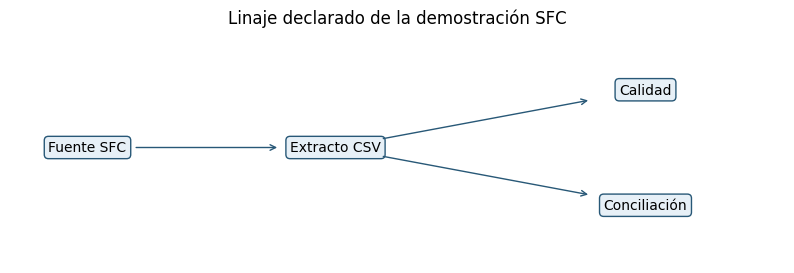

In [3]:
fig,ax=plt.subplots(figsize=(10,3));ax.axis('off')
pos={'Fuente SFC':(0.1,0.5),'Extracto CSV':(0.42,0.5),'Calidad':(0.82,0.75),'Conciliación':(0.82,0.25)}
for label,(x,y) in pos.items(): ax.text(x,y,label,ha='center',va='center',bbox=dict(boxstyle='round',fc='#e7f0f7',ec='#285877'))
for a,b in [('Fuente SFC','Extracto CSV'),('Extracto CSV','Calidad'),('Extracto CSV','Conciliación')]:
    ax.annotate('',xy=pos[b],xytext=pos[a],arrowprops=dict(arrowstyle='->',shrinkA=35,shrinkB=42,color='#285877'))
ax.set_title('Linaje declarado de la demostración SFC');plt.show()

## Interpretación
Si el extracto cambia, los dos notebooks identificados requieren revisión y reejecución. La cuenta de dos consumidores se limita a los declarados; otros componentes pueden depender del archivo. No se asignan probabilidades de fallo sin observaciones de incidentes ni se infiere criticidad financiera a partir del grado del nodo.